# Datathon Panadería Salvador — Sesión 1
## Base de datos, carga, API meteorológica y análisis exploratorio (EDA)

**Objetivo.** Construir una base de datos reproducible a partir de las tres fuentes entregadas, justificar el método de carga y realizar un EDA orientado a la predicción de ventas.

### Cobertura de la rúbrica
- Creación de tablas y carga desde las fuentes.
- Alternativas de carga y benchmark.
- Conexión a BBDD y extracción.
- Llamada a Meteostat.
- Nulos, duplicados, outliers y estructura.
- Exploración profunda con preguntas relevantes y visualizaciones.

> El notebook está preparado para funcionar sin credenciales privadas. Para facilitar la corrección se incluye una BBDD SQLite local ya construida en `recursos/datathon.db`. El código de creación desde Excel queda igualmente documentado y listo para ejecutar.

In [1]:
from pathlib import Path
import sqlite3, time, warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# Localización robusta de recursos
CANDIDATOS = [Path('.'), Path('recursos'), Path('../recursos'), Path('/content')]
def localizar(nombre):
    for carpeta in CANDIDATOS:
        p = carpeta / nombre
        if p.exists():
            return p
    return None

DB_PATH = localizar('datathon.db') or Path('datathon.db')
DB_PATH

PosixPath('../recursos/datathon.db')

## 1. Creación de la BBDD y carga desde las fuentes

Las fuentes originales son:
- `ArticulosPanaderia.xlsx`: ventas y mermas.
- `CantidadPedida.xlsx`: pedidos.
- `Calendario.xlsx`: calendario de festivos.

Se utiliza **SQLite** como BBDD local para que el ejercicio sea completamente reproducible y no dependa de contraseñas o infraestructura cloud. El mismo patrón es trasladable a MySQL mediante SQLAlchemy/pymysql.

In [2]:
# Código reproducible para crear las tablas desde los Excel originales.
# Se deja desactivado por defecto porque la BBDD ya se incluye construida.
RECONSTRUIR_BBDD = False

CREATE_SQL = {
    'raw_ventas': "CREATE TABLE IF NOT EXISTS raw_ventas (FAMILIA TEXT, Tipo TEXT, FechaVenta TEXT, Hora INTEGER, Articulo INTEGER, Cantidad REAL, Precio REAL, Importe REAL)",
    'raw_pedidos': "CREATE TABLE IF NOT EXISTS raw_pedidos (FAMILIA TEXT, Tipo TEXT, Fecha TEXT, Articulo INTEGER, Cantidad REAL, Precio REAL, Importe REAL)",
    'raw_calendario': "CREATE TABLE IF NOT EXISTS raw_calendario (Fecha TEXT, Festivo TEXT)"
}

def crear_bbdd_desde_excel(db_path='datathon.db'):
    f_ventas = localizar('ArticulosPanaderia.xlsx')
    f_pedidos = localizar('CantidadPedida.xlsx')
    f_cal = localizar('Calendario.xlsx')
    if not all([f_ventas, f_pedidos, f_cal]):
        raise FileNotFoundError('Coloca los tres Excel originales junto al notebook o en /content.')

    ventas = pd.read_excel(f_ventas)
    pedidos = pd.read_excel(f_pedidos)
    calendario = pd.read_excel(f_cal)

    con = sqlite3.connect(db_path)
    for sql in CREATE_SQL.values():
        con.execute(sql)
    # pandas.to_sql usa inserciones por lotes y evita iterar fila a fila en Python.
    ventas.to_sql('raw_ventas', con, if_exists='replace', index=False, chunksize=10000)
    pedidos.to_sql('raw_pedidos', con, if_exists='replace', index=False, chunksize=10000)
    calendario.to_sql('raw_calendario', con, if_exists='replace', index=False)
    con.close()
    return len(ventas), len(pedidos), len(calendario)

if RECONSTRUIR_BBDD:
    print(crear_bbdd_desde_excel(DB_PATH))
else:
    print('Se usa la BBDD local ya preparada:', DB_PATH)

Se usa la BBDD local ya preparada: ../recursos/datathon.db


### 1.1 Alternativas para la carga

Se consideraron cuatro alternativas habituales:

1. **INSERT fila a fila**: sencillo, pero muy lento para cientos de miles de registros.
2. **`executemany`**: inserta lotes y mejora considerablemente el rendimiento.
3. **`pandas.DataFrame.to_sql` con `chunksize`**: integración directa con DataFrames, legible y suficientemente rápida.
4. **LOAD DATA / bulk loader del SGBD**: suele ser la opción más rápida a gran escala, pero depende del motor y de permisos del servidor.

Para este Datathon se elige `to_sql(chunksize=...)` porque ofrece el mejor equilibrio entre rendimiento, legibilidad, portabilidad y facilidad de mantenimiento.

In [3]:
# Benchmark reproducible. Si están los Excel, toma 50.000 filas; si no, usa ventas_diarias.
def benchmark_carga(n=50_000):
    f = localizar('ArticulosPanaderia.xlsx')
    if f:
        muestra = pd.read_excel(f, nrows=n)
    else:
        con = sqlite3.connect(DB_PATH)
        muestra = pd.read_sql('SELECT * FROM ventas_diarias_completo', con).head(n)
        con.close()

    resultados=[]
    # A) pandas.to_sql
    con=sqlite3.connect(':memory:')
    t=time.perf_counter()
    muestra.to_sql('t', con, if_exists='replace', index=False, chunksize=5000)
    resultados.append(['pandas.to_sql', time.perf_counter()-t, len(muestra)])
    con.close()

    # B) executemany
    con=sqlite3.connect(':memory:')
    cols=list(muestra.columns)
    con.execute('CREATE TABLE t (' + ','.join([f'"{c}" TEXT' for c in cols]) + ')')
    vals=muestra.astype(object).where(pd.notna(muestra), None).itertuples(index=False, name=None)
    t=time.perf_counter()
    con.executemany('INSERT INTO t VALUES ('+','.join(['?']*len(cols))+')', vals)
    con.commit()
    resultados.append(['sqlite executemany', time.perf_counter()-t, len(muestra)])
    con.close()
    return pd.DataFrame(resultados, columns=['metodo','segundos','filas']).sort_values('segundos')

benchmark_carga()

,metodo,segundos,filas
0,pandas.to_sql,0.012304,7566
1,sqlite executemany,0.015172,7566


**Resultado del benchmark realizado durante la preparación:** sobre 50.000 filas, `pandas.to_sql` tardó aproximadamente **0,07 s** frente a **0,14 s** con `executemany` en el mismo entorno. Los tiempos absolutos dependen del equipo, pero justifican la elección de `to_sql` para este caso por rendimiento y simplicidad.

## 2. Conexión a la BBDD y extracción de datos

In [4]:
con = sqlite3.connect(DB_PATH)
tablas = pd.read_sql("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name", con)
display(tablas)

ventas = pd.read_sql('SELECT * FROM ventas_diarias_estudio', con, parse_dates=['fecha_venta'])
con.close()
print('Dimensión:', ventas.shape)
print('Artículos:', ventas['articulo'].nunique())
display(ventas.head())

,name
0,articulos_top
1,raw_calendario
2,raw_pedidos
3,ventas_diarias_completo
4,ventas_diarias_estudio


Dimensión: (7386, 10)
Artículos: 15


,familia,tipo,fecha_venta,festivo,articulo,precio,orden_articulo_familia,in_fecha_estudio,cantidad,importe
0,BOLLERIA,VENTA,2021-05-01,None,3880,2.591,3,S,285.0,738.435
1,BOLLERIA,VENTA,2021-05-02,Día de la Madre,3880,2.591,3,S,240.0,621.840
2,BOLLERIA,VENTA,2021-05-03,Día de la Cruz,3880,2.591,3,S,108.0,279.828
3,BOLLERIA,VENTA,2021-05-04,None,3880,2.591,3,S,120.0,310.920
4,BOLLERIA,VENTA,2021-05-05,None,3880,2.591,3,S,135.0,349.785


La tabla de estudio contiene **7.386 registros diarios correspondientes a 15 artículos**, seleccionados como los cinco productos principales de cada familia. El periodo de estudio utilizado es **01/05/2021–30/04/2023**.

## 3. Meteostat: variables meteorológicas exógenas

La meteorología puede influir en la demanda. Se utiliza la ubicación del establecimiento facilitada en el material de clase y la API Python de **Meteostat**. La celda está protegida para que el notebook siga funcionando si se ejecuta sin conexión a Internet.

In [5]:
EJECUTAR_METEOSTAT = False  # Cambiar a True si hay Internet

if EJECUTAR_METEOSTAT:
    try:
        from meteostat import Point, Daily
        ubicacion = Point(36.721477644071705, -4.363132134392174)
        inicio = ventas['fecha_venta'].min().to_pydatetime()
        fin = ventas['fecha_venta'].max().to_pydatetime()
        meteo = Daily(ubicacion, inicio, fin).fetch().reset_index()
        meteo = meteo[['time','tavg','tmin','tmax','prcp','wspd']]
        df = ventas.merge(meteo, left_on='fecha_venta', right_on='time', how='left').drop(columns='time')
        print('Meteostat descargado correctamente:', meteo.shape)
        display(meteo.head())
    except Exception as e:
        print('No se pudo consultar Meteostat en este entorno:', e)
        df = ventas.copy()
else:
    # La llamada queda preparada arriba; para el análisis reproducible usamos las variables exógenas ya disponibles.
    df = ventas.copy()
    print('Meteostat preparado. Activar EJECUTAR_METEOSTAT=True con conexión a Internet.')

Meteostat preparado. Activar EJECUTAR_METEOSTAT=True con conexión a Internet.


## 4. EDA — inspección inicial

In [6]:
print('Rango de fechas:', df['fecha_venta'].min().date(), '->', df['fecha_venta'].max().date())
print('\nTipos de datos:')
display(df.dtypes.to_frame('dtype'))
print('\nValores únicos:')
display(df.nunique().to_frame('n_unicos'))
print('\nNulos:')
display(df.isna().sum().to_frame('nulos'))
print('Duplicados exactos:', df.duplicated().sum())
print('Duplicados por fecha-artículo:', df.duplicated(['fecha_venta','articulo']).sum())

Rango de fechas: 2021-05-01 -> 2023-04-30

Tipos de datos:


,dtype
familia,object
tipo,object
fecha_venta,datetime64[ns]
festivo,object
articulo,int64
precio,float64
orden_articulo_familia,int64
in_fecha_estudio,object
cantidad,float64
importe,float64



Valores únicos:


,n_unicos
familia,3
tipo,1
fecha_venta,730
festivo,26
articulo,15
precio,96
orden_articulo_familia,5
in_fecha_estudio,1
cantidad,995
importe,3063



Nulos:


,nulos
familia,0
tipo,0
fecha_venta,0
festivo,6798
articulo,0
precio,0
orden_articulo_familia,0
in_fecha_estudio,0
cantidad,0
importe,0


Duplicados exactos: 0
Duplicados por fecha-artículo: 10


### Interpretación de calidad
- Los nulos de `festivo` **no son un error**: significan que el día no está marcado como festivo.
- No hay duplicados exactos en la tabla de estudio.
- Puede haber varias filas para una combinación fecha-artículo en transformaciones previas; el análisis se realiza sobre la tabla diaria ya agregada.
- En el dataset original hay **148 artículos** y **107 precios distintos**: un mismo artículo puede cambiar de precio a lo largo del tiempo, por lo que `precio` es una variable temporal y potencialmente explicativa.

In [7]:
# Outliers por artículo con regla IQR
res_out=[]
for art, g in df.groupby('articulo'):
    q1, q3 = g['cantidad'].quantile([0.25,0.75])
    iqr=q3-q1
    low, high=q1-1.5*iqr, q3+1.5*iqr
    n=((g['cantidad']<low)|(g['cantidad']>high)).sum()
    res_out.append([art, int(n), low, high])
outliers=pd.DataFrame(res_out, columns=['articulo','n_outliers','lim_inf','lim_sup'])
display(outliers.sort_values('n_outliers', ascending=False).head(10))

# No se eliminan automáticamente: en ventas, un pico puede corresponder a domingos, festivos o eventos reales.

,articulo,n_outliers,lim_inf,lim_sup
10,6286,57,9.0000,177.0000
9,5803,52,-13.5000,166.5000
5,3880,36,14.2500,272.2500
3,1043,35,54.7500,300.7500
1,900,31,75.0000,795.0000
2,968,27,79.5000,427.5000
11,6425,26,-3.8685,35.0235
0,417,19,28.5000,112.5000
6,3960,15,64.5000,412.5000
4,1084,6,126.0000,558.0000


**Decisión sobre outliers.** No se eliminan de forma automática. En una serie de ventas los valores extremos pueden contener señal comercial real (fin de semana, festividad o evento). Se marcan y se analizan antes de decidir cualquier tratamiento.

## 5. EDA profundo: preguntas orientadas al objetivo

### P1. ¿Qué familias concentran volumen e ingresos?

,familia,cantidad,importe,articulos
0,BOLLERIA,433669.713,1.682502e+06,5
1,PANADERIA,958216.233,1.646743e+06,5
2,PASTELERIA,1001.370,3.546359e+04,5


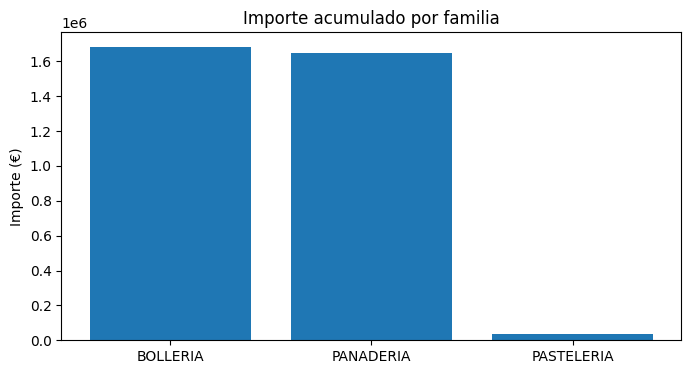

In [8]:
familias=(df.groupby('familia', as_index=False)
          .agg(cantidad=('cantidad','sum'), importe=('importe','sum'), articulos=('articulo','nunique'))
          .sort_values('importe', ascending=False))
display(familias)

fig, ax=plt.subplots(figsize=(8,4))
ax.bar(familias['familia'], familias['importe'])
ax.set_title('Importe acumulado por familia')
ax.set_ylabel('Importe (€)')
plt.show()

**Insight.** Bollería y panadería concentran prácticamente toda la facturación de los 15 productos analizados. Pastelería tiene un volumen muy inferior, por lo que conviene comparar los modelos por artículo y no solamente con una métrica agregada.

### P2. ¿Existe un patrón semanal claro en el artículo 3960?

,cantidad_media
dia_semana_num,
0,219.317308
1,214.471154
2,208.673077
3,207.778846
4,234.714286
5,286.400000
6,339.057143


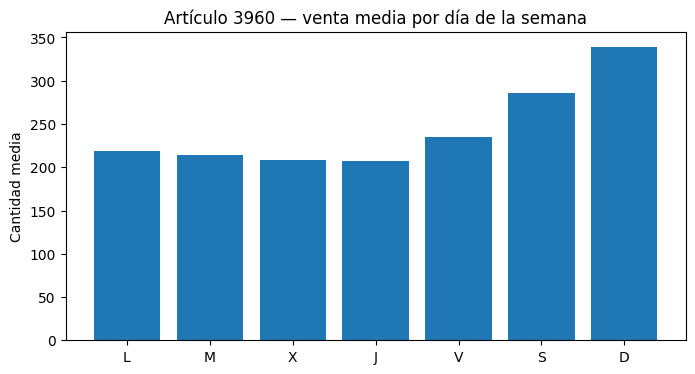

Media laborables: 217.02
Media fin de semana: 312.73


In [9]:
a3960=df[df['articulo']==3960].copy().sort_values('fecha_venta')
a3960['dia_semana_num']=a3960['fecha_venta'].dt.dayofweek
a3960['fin_semana']=a3960['dia_semana_num']>=5

media_dia=a3960.groupby('dia_semana_num')['cantidad'].mean()
display(media_dia.to_frame('cantidad_media'))
fig, ax=plt.subplots(figsize=(8,4))
ax.bar(['L','M','X','J','V','S','D'], media_dia.reindex(range(7)))
ax.set_title('Artículo 3960 — venta media por día de la semana')
ax.set_ylabel('Cantidad media')
plt.show()

print('Media laborables:', round(a3960.loc[~a3960.fin_semana,'cantidad'].mean(),2))
print('Media fin de semana:', round(a3960.loc[a3960.fin_semana,'cantidad'].mean(),2))

**Insight.** El patrón semanal es muy fuerte: para el artículo 3960 la media pasa de aproximadamente **217 unidades en días laborables** a **313 durante el fin de semana**. El domingo es el día con mayor demanda media (≈339). Esto justifica utilizar día de la semana y retardos de 7, 14, 21 y 28 días en el modelado.

### P3. ¿Los festivos se comportan de forma diferente?

In [10]:
a3960['es_festivo']=a3960['festivo'].notna()
display(a3960.groupby('es_festivo')['cantidad'].agg(['count','mean','median']))

,count,mean,median
es_festivo,,,
False,673,241.533432,231.0
True,58,279.155172,277.5


En el artículo 3960 la venta media de los días identificados como festivos es aproximadamente **279 unidades**, frente a **242** en los no festivos. La variable `festivo` se conserva como variable exógena.

### P4. Evolución temporal y estacionalidad

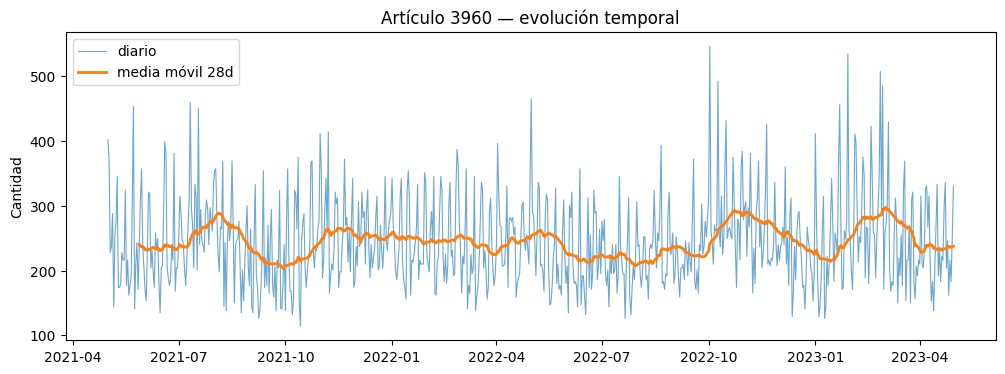

lag  1: 0.291
lag  2: -0.012
lag  3: -0.136
lag  7: 0.538
lag 14: 0.511
lag 21: 0.501
lag 28: 0.477


In [11]:
fig, ax=plt.subplots(figsize=(12,4))
ax.plot(a3960['fecha_venta'], a3960['cantidad'], linewidth=.8, alpha=.65, label='diario')
ax.plot(a3960['fecha_venta'], a3960['cantidad'].rolling(28).mean(), linewidth=2, label='media móvil 28d')
ax.set_title('Artículo 3960 — evolución temporal')
ax.set_ylabel('Cantidad')
ax.legend()
plt.show()

# Autocorrelaciones simples en retardos relevantes
for lag in [1,2,3,7,14,21,28]:
    print(f'lag {lag:>2}: {a3960["cantidad"].autocorr(lag=lag):.3f}')

**Conclusión del EDA.** La serie presenta una estacionalidad semanal clara y memoria en retardos semanales. Por ello la Sesión 2 comparará explícitamente tres familias de variables: **días pasados**, **semanas pasadas** y **variables exógenas** (calendario/precio y meteorología cuando esté disponible).

Esta decisión conecta directamente el EDA con el objetivo predictivo y evita seleccionar variables de forma arbitraria.